In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
dataset = '/content/drive/MyDrive/Datasets/Merged_Files/era5_delhi_1981_2025.nc'
dataset

'/content/drive/MyDrive/Datasets/Merged_Files/era5_delhi_1981_2025.nc'

In [3]:

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

dsf = xr.open_dataset(dataset)
dsf

<xarray.Dataset> Size: 5MB
Dimensions:     (valid_time: 6885, latitude: 5, longitude: 5)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 55kB 1981-03-01T12:00:00 ... 2025...
  * latitude    (latitude) float64 40B 29.0 28.75 28.5 28.25 28.0
  * longitude   (longitude) float64 40B 76.5 76.75 77.0 77.25 77.5
    number      int64 8B ...
    expver      (valid_time) <U4 110kB ...
Data variables:
    tp          (valid_time, latitude, longitude) float32 688kB ...
    ssrd        (valid_time, latitude, longitude) float32 688kB ...
    t2m         (valid_time, latitude, longitude) float32 688kB ...
    d2m         (valid_time, latitude, longitude) float32 688kB ...
    sp          (valid_time, latitude, longitude) float32 688kB ...
    u10         (valid_time, latitude, longitude) float32 688kB ...
    v10         (valid_time, latitude, longitude) float32 688kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-01-24T09:09 GRIB to CDM+CF via cfgrib-0.9.1...

In [4]:
import numpy as np
import tensorflow as tf
import random

seed = 42
np.random.seed(seed)
tf.random.set_seed(seed)
random.seed(seed)

In [5]:
dsf.coords

Coordinates:
  * valid_time  (valid_time) datetime64[ns] 55kB 1981-03-01T12:00:00 ... 2025...
  * latitude    (latitude) float64 40B 29.0 28.75 28.5 28.25 28.0
  * longitude   (longitude) float64 40B 76.5 76.75 77.0 77.25 77.5
    number      int64 8B ...
    expver      (valid_time) <U4 110kB ...

In [6]:
print(dsf.latitude.values)
print(dsf.longitude.values)

[29.   28.75 28.5  28.25 28.  ]
[76.5  76.75 77.   77.25 77.5 ]


In [7]:
print(dsf.valid_time.min().values)
print(dsf.valid_time.max().values)

1981-03-01T12:00:00.000000000
2025-07-31T12:00:00.000000000


In [8]:
dsf.valid_time.diff("valid_time").to_pandas().value_counts()

,count
valid_time,
1 days,6840
213 days,33
214 days,11


In [9]:
print(dsf.isnull().sum())

<xarray.Dataset> Size: 64B
Dimensions:  ()
Coordinates:
    number   int64 8B ...
Data variables:
    tp       int64 8B 0
    ssrd     int64 8B 0
    t2m      int64 8B 0
    d2m      int64 8B 0
    sp       int64 8B 0
    u10      int64 8B 0
    v10      int64 8B 0
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-01-24T09:09 GRIB to CDM+CF via cfgrib-0.9.1...


In [10]:
dsf = dsf.sortby("valid_time")

In [11]:
list(dsf.data_vars)

['tp', 'ssrd', 't2m', 'd2m', 'sp', 'u10', 'v10']

In [12]:
dsf["t2m_C"] = dsf["t2m"] - 273.15
dsf["d2m_C"] = dsf["d2m"] - 273.15


In [13]:
print(dsf["t2m_C"].mean().values)
print(dsf["t2m_C"].max().values)

34.32028579711914
46.547271728515625


In [14]:
import numpy as np

def compute_rh(t, td):
    return 100 * (
        np.exp((17.625 * td) / (243.04 + td)) /
        np.exp((17.625 * t) / (243.04 + t))
    )

dsf["RH"] = compute_rh(dsf["t2m_C"], dsf["d2m_C"])


In [15]:
print(dsf["RH"].min().values)
print(dsf["RH"].max().values)


5.334019184112549
100.01123046875


In [16]:
def compute_hi_optimized(T, RH):
    # Standard Metric Rothfusz Coefficients
    HI = (
        -8.784695 +
        1.61139411 * T +
        2.338549 * RH -
        0.14611605 * T * RH -
        0.012308094 * T**2 -
        0.016424828 * RH**2 +
        0.002211732 * T**2 * RH +
        0.00072546 * T * RH**2 -
        0.000003582 * T**2 * RH**2
    )
    # NOAA rule: HI is only applicable above 26.7°C and RH > 40%
    # For a deep learning target, keeping it simple with T >= 26.7 is standard.
    return xr.where((T >= 26.7) & (RH >= 40), HI, T)

dsf["HI_C"] = compute_hi_optimized(dsf["t2m_C"], dsf["RH"])

In [17]:
dsf["HI_C"].max().values

array(55.70609283)

In [18]:
dsf["HI_C"].to_numpy().flatten()

array([22.375732, 22.166748, 22.164795, ..., 33.138847, 34.07428 ,
       33.629387], dtype=float32)

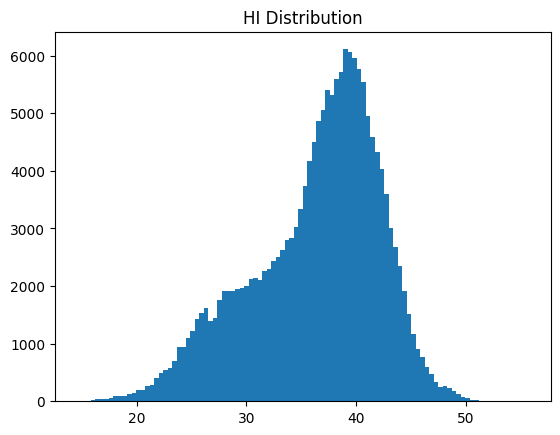

array([42.93259125, 44.25263138, 46.93567383])

In [19]:
plt.hist(dsf["HI_C"].values.flatten(), bins=100)
plt.title("HI Distribution")
plt.show()

np.percentile(dsf["HI_C"].values.flatten(), [90, 95, 99])

In [20]:
import warnings
warnings.filterwarnings('ignore')

# HI stress classification (0–2)
def hi_stress_class(hi):
    return xr.where(
        hi < 35, 0,
        xr.where(hi < 40, 1, 2)
    )

dsf["HI_stress"] = hi_stress_class(dsf["HI_C"])


In [21]:
# dsf['HI_C_lag_1'] = dsf['HI_C'].shift(valid_time=1)
# dsf["HI_C_lag_2"] = dsf['HI_C'].shift(valid_time = 2)
# dsf["HI_C_lag_3"] = dsf['HI_C'].shift(valid_time = 3)

# dsf = dsf.dropna(dim="valid_time")


# No lag features needed for now, as they are redundant for LSTM model, as it already sees context that we are definin gfor 30 days, leading to huge auto-correlation

In [22]:
# np.unique(dsf["HI_stress"], return_counts=True)

# Check class distribution
import numpy as np

classes, counts = np.unique(dsf["HI_stress"].values.flatten(), return_counts=True)

for c, cnt in zip(classes, counts):
    print(f"Class {c}: {cnt} samples ({cnt / counts.sum() * 100:.2f}%)")

Class 0: 58577 samples (34.03%)
Class 1: 62511 samples (36.32%)
Class 2: 51037 samples (29.65%)


In [23]:
np.percentile(dsf["HI_C"].values.flatten(), [90, 95, 99])

array([42.93259125, 44.25263138, 46.93567383])

In [24]:
dsf["HI_C"].max().values

array(55.70609283)

In [25]:
extreme_ratio = (dsf["HI_C"] >= 40).mean(dim=["valid_time"])
print(extreme_ratio)

<xarray.DataArray 'HI_C' (latitude: 5, longitude: 5)> Size: 200B
array([[0.31285403, 0.29774873, 0.28641975, 0.28090051, 0.27421932],
       [0.33144517, 0.31053014, 0.29934641, 0.2929557 , 0.28743646],
       [0.31619463, 0.3070443 , 0.29891068, 0.29251997, 0.29484386],
       [0.29803922, 0.29455338, 0.29513435, 0.30108932, 0.30791576],
       [0.25432099, 0.26419753, 0.29324619, 0.30936819, 0.31154684]])
Coordinates:
  * latitude   (latitude) float64 40B 29.0 28.75 28.5 28.25 28.0
  * longitude  (longitude) float64 40B 76.5 76.75 77.0 77.25 77.5
    number     int64 8B 0
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      25
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                        

In [26]:
dsf['HI_C_tomorow'] = dsf['HI_C'].shift(valid_time=-1)

In [27]:
dsf.isnull().sum()

<xarray.Dataset> Size: 112B
Dimensions:       ()
Coordinates:
    number        int64 8B 0
Data variables: (12/13)
    tp            int64 8B 0
    ssrd          int64 8B 0
    t2m           int64 8B 0
    d2m           int64 8B 0
    sp            int64 8B 0
    u10           int64 8B 0
    ...            ...
    t2m_C         int64 8B 0
    d2m_C         int64 8B 0
    RH            int64 8B 0
    HI_C          int64 8B 0
    HI_stress     int64 8B 0
    HI_C_tomorow  int64 8B 25
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-01-24T09:09 GRIB to CDM+CF via cfgrib-0.9.1...

In [28]:
import pandas as pd

df_flat = dsf[["t2m_C","RH","ssrd","u10","v10","HI_C","HI_C_tomorow", "d2m_C"]].to_dataframe().dropna()

df_flat.corr()["HI_C_tomorow"].sort_values(ascending=False)

,HI_C_tomorow
HI_C_tomorow,1.000000
HI_C,0.861669
t2m_C,0.725374
ssrd,0.395283
d2m_C,0.393270
u10,0.019629
v10,0.005075
RH,-0.024573
number,NaN
expver,NaN


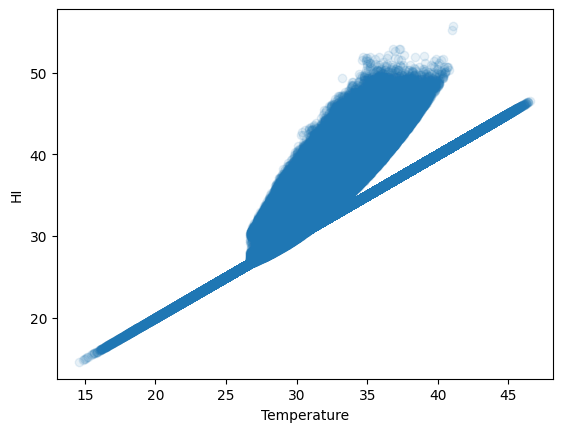

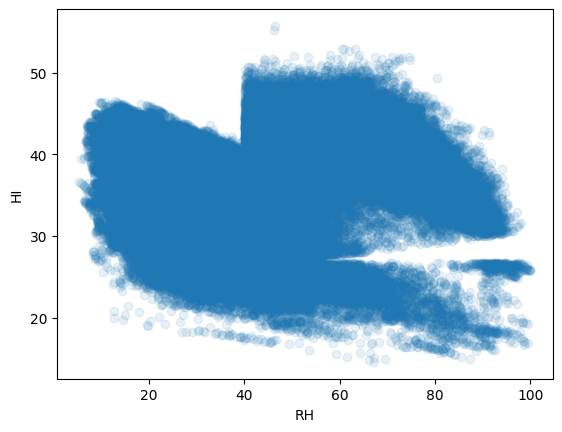

In [29]:
import matplotlib.pyplot as plt

plt.scatter(df_flat["t2m_C"], df_flat["HI_C"], alpha=0.1)
plt.xlabel("Temperature")
plt.ylabel("HI")
plt.show()

plt.scatter(df_flat["RH"], df_flat["HI_C"], alpha=0.1)
plt.xlabel("RH")
plt.ylabel("HI")
plt.show()

In [30]:
df_flat["temp_rh"] = df_flat["t2m_C"] * df_flat["RH"]
df_flat.corr()["HI_C_tomorow"]

,HI_C_tomorow
t2m_C,0.725374
RH,-0.024573
ssrd,0.395283
u10,0.019629
v10,0.005075
HI_C,0.861669
HI_C_tomorow,1.000000
d2m_C,0.393270
number,NaN
expver,NaN


In [31]:
dsf["wind_speed"] = np.sqrt(dsf["u10"]**2 + dsf["v10"]**2)

In [32]:
dsf["temp_sq"] = dsf["t2m_C"] ** 2
dsf["rh_sq"] = dsf["RH"] ** 2
dsf["temp_rh"] = dsf["t2m_C"] * dsf["RH"]

In [33]:
dsf["temp_diff"] = dsf["t2m_C"] - dsf["d2m_C"]

In [34]:
# 🔹 Lag Features (ONLY 1-step)
dsf["HI_C_lag1"] = dsf["HI_C"].shift(valid_time=1)
dsf["t2m_lag1"] = dsf["t2m_C"].shift(valid_time=1)
dsf["d2m_lag1"] = dsf["d2m_C"].shift(valid_time=1)

# Drop NaNs after lag
dsf = dsf.dropna(dim="valid_time")

In [35]:
# 🔹 Trend Features (rate of change)
dsf["t2m_trend"] = dsf["t2m_C"] - dsf["t2m_C"].shift(valid_time=1)
dsf["d2m_trend"] = dsf["d2m_C"] - dsf["d2m_C"].shift(valid_time=1)
dsf["HI_C_trend"]  = dsf["HI_C"]  - dsf["HI_C"].shift(valid_time=1)

# Drop NaNs again
dsf = dsf.dropna(dim="valid_time")

In [36]:
# features = [
#     "t2m_C",
#     "d2m_C",
#     "RH",
#     "ssrd",
#     "u10",
#     "v10"
# ]

# features = [
#     "t2m_C",
#     "d2m_C",
#     "RH",
#     "ssrd",
#     "wind_speed",
#     "temp_sq",
#     "rh_sq",
#     "temp_rh"
# ]

features = [
    "t2m_C",
    "d2m_C",
    "RH",
    "ssrd",
    "wind_speed",
    "temp_sq",
    "rh_sq",
    "temp_rh",
    "tp",
    "sp",
    "HI_C",
    "HI_C_lag1",
    "t2m_lag1",
    "d2m_lag1",
    "temp_diff",
    "HI_C_trend",
    "d2m_trend",
    "t2m_trend"
]

In [37]:
X = dsf[features].to_array().transpose(
    "valid_time", "variable", "latitude", "longitude"
)

y_reg = dsf["HI_C_tomorow"]
y_cls = dsf["HI_stress"]

X.shape, y_reg.shape, y_cls.shape

((6882, 18, 5, 5), (6882, 5, 5), (6882, 5, 5))

In [38]:
# lat_idx = dsf.dims["latitude"] // 2
# lon_idx = dsf.dims["longitude"] // 2

# y_reg_center = y_reg.isel(latitude=lat_idx, longitude=lon_idx).values
# y_cls_center = y_cls.isel(latitude=lat_idx, longitude=lon_idx).values


In [39]:
import numpy as np

def make_sequences(X, y, input_len=30, output_len=3):
    X_seq = []
    y_seq = []

    for i in range(len(X) - input_len - output_len):
        X_seq.append(X[i:i+input_len])  # (30, features, 5, 5)
        y_seq.append(y[i+input_len:i+input_len+output_len])  # (7, 5, 5)

    return np.array(X_seq), np.array(y_seq)


X_np = X.values
y_reg_np = y_reg.values

X_seq, y_reg_seq = make_sequences(X_np, y_reg_np)

print(X_seq.shape, y_reg_seq.shape)

(6849, 30, 18, 5, 5) (6849, 3, 5, 5)


In [40]:
# from tensorflow.keras.utils import to_categorical

# y_cls_oh = to_categorical(y_cls_seq, num_classes=3)


In [41]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks

# X_seq shape: (samples, 30, features, 5, 5)
# Move channels last for Conv ops
X_seq = X_seq.transpose(0, 1, 3, 4, 2)  # (samples, 30, 5, 5, features)

In [42]:
split_1 = int(0.7 * len(X_seq))
split_2 = int(0.85 * len(X_seq))

X_train, y_train = X_seq[:split_1], y_reg_seq[:split_1]
X_val, y_val = X_seq[split_1:split_2], y_reg_seq[split_1:split_2]
X_test, y_test = X_seq[split_2:], y_reg_seq[split_2:]

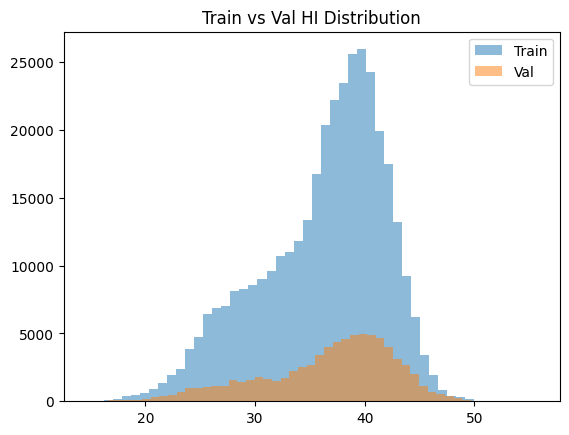

In [43]:
import matplotlib.pyplot as plt

plt.hist(y_train.flatten(), bins=50, alpha=0.5, label="Train")
plt.hist(y_val.flatten(), bins=50, alpha=0.5, label="Val")
plt.legend()
plt.title("Train vs Val HI Distribution")
plt.show()

In [44]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# reshape for scaling
X_train_reshaped = X_train.reshape(-1, X_train.shape[-1])
X_val_reshaped = X_val.reshape(-1, X_val.shape[-1])
X_test_reshaped = X_test.reshape(-1, X_test.shape[-1])

# fit ONLY on train
scaler.fit(X_train_reshaped)

# transform
X_train = scaler.transform(X_train_reshaped).reshape(X_train.shape)
X_val = scaler.transform(X_val_reshaped).reshape(X_val.shape)
X_test = scaler.transform(X_test_reshaped).reshape(X_test.shape)

In [45]:
# input_layer = layers.Input(shape=(30, 5, 5, len(features)))

# # Spatial
# x = layers.TimeDistributed(
#     layers.Conv2D(32, (3,3), padding="same", activation="relu")
# )(input_layer)

# x = layers.TimeDistributed(layers.MaxPooling2D((2,2)))(x)
# x = layers.TimeDistributed(layers.GlobalAveragePooling2D())(x)

# x = layers.Bidirectional(
#     layers.GRU(128, return_sequences=False)
# )(x)

# # Output
# x = layers.Dense(128, activation="relu")(x)
# x = layers.Dropout(0.3)(x)

# output = layers.Dense(3 * 5 * 5)(x)
# output = layers.Reshape((3, 5, 5))(output)

# model = models.Model(inputs=input_layer, outputs=output)



input_layer = layers.Input(shape=(30, 5, 5, len(features)))

# Spatial
x = layers.TimeDistributed(
    layers.Conv2D(32, (3,3), padding="same", activation="relu")
)(input_layer)

# x = layers.TimeDistributed(layers.MaxPooling2D((2,2)))(x)

x = layers.TimeDistributed(
    layers.Conv2D(32, (3,3), padding="same", activation="relu")
)(x)

x = layers.TimeDistributed(layers.GlobalAveragePooling2D())(x)

# Temporal (GRU ONLY)
x = layers.Bidirectional(
    layers.GRU(64, return_sequences=False))(x)

x = layers.LayerNormalization()(x)

# Dense
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.2)(x)

# Output (3-day)
output = layers.Dense(3 * 5 * 5)(x)
output = layers.Reshape((3, 5, 5))(output)

model = models.Model(inputs=input_layer, outputs=output)

In [46]:
# model_gru = build_gru_model()
# model_lstm = build_lstm_model()

In [47]:
# def weighted_mse(y_true, y_pred):
#     weights = tf.where(y_true >= 40, 4.0,
#                tf.where(y_true >= 35, 2.0, 1.0))

#     return tf.reduce_mean(weights * tf.square(y_true - y_pred))

def mixed_loss(y_true, y_pred):
    weights = tf.where(y_true >= 40, 4.0,
               tf.where(y_true >= 35, 2.0, 1.0))

    mse = tf.reduce_mean(weights * tf.square(y_true - y_pred))
    mae = tf.reduce_mean(tf.abs(y_true - y_pred))

    return 0.7 * mse + 0.3 * mae

In [48]:
model.compile(
    optimizer=optimizers.Adam(learning_rate=3e-4),
    loss=mixed_loss,
    metrics=["mae"]
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 5, 5, 18)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 5, 5, 32)   │         5,216 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 30, 5, 5, 32)   │         9,248 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 30, 32)         │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        37,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 75)             │         9,675 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 3, 5, 5)        │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,539 (306.79 KB)

 Trainable params: 78,539 (306.79 KB)

 Non-trainable params: 0 (0.00 B)

In [70]:
es = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    mode = 'min',
    restore_best_weights=True,
    min_delta = 0.0001,
    verbose = 1
)

# Reduce LR (more responsive)
reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    mode='min',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val), # Corrected: use validation_data instead of validation_split
    epochs=100,
    batch_size=16,
    callbacks=[es, reduce_lr],
    verbose=1
)

Epoch 1/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - loss: 21.1968 - mae: 2.9405 - val_loss: 17.3267 - val_mae: 2.5355 - learning_rate: 1.0000e-06
Epoch 2/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - loss: 21.7079 - mae: 2.9879 - val_loss: 17.2921 - val_mae: 2.5375 - learning_rate: 1.0000e-06
Epoch 3/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - loss: 21.0580 - mae: 2.9545 - val_loss: 17.3104 - val_mae: 2.5361 - learning_rate: 1.0000e-06
Epoch 4/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 20.8293 - mae: 2.9252 - val_loss: 17.3028 - val_mae: 2.5368 - learning_rate: 1.0000e-06
Epoch 5/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - loss: 21.0487 - mae: 2.9237 - val_loss: 17.3101 - val_mae: 2.5362 - learning_rate: 1.0000e-06
Epoch 6/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - loss: 21.3861 - mae: 2.9689 - val_loss: 17.2749 - val_mae: 2.5380 - learning_rate: 1.0000e-06
Epoch 7/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - loss: 21.1635 - mae: 2.9345 - val_loss: 17.

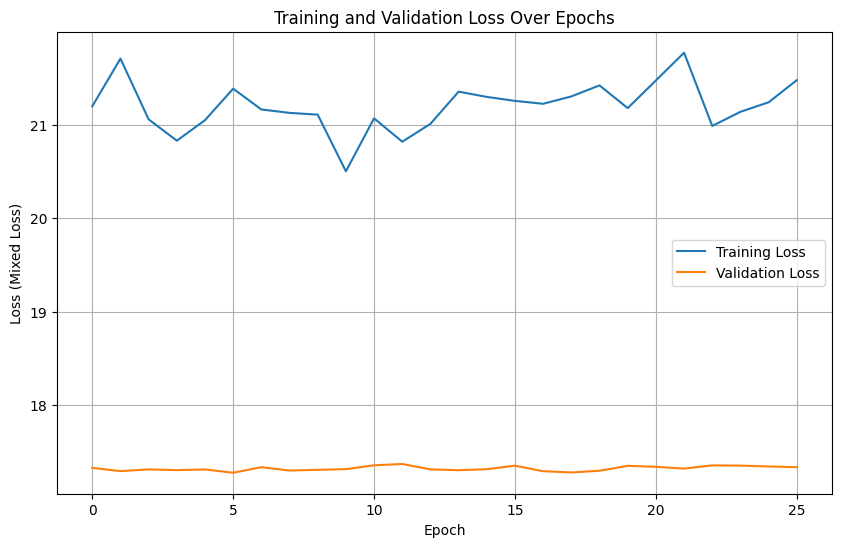

In [71]:
import matplotlib.pyplot as plt

# Plot training and validation loss
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss (Mixed Loss)')
plt.legend()
plt.grid(True)
plt.show()


In [72]:
# Predict
y_pred_val = model.predict(X_val)

y_pred_val = y_pred_val + 0.3

# Basic metrics
mae = tf.reduce_mean(tf.abs(y_pred_val - y_val)).numpy()
print("Overall MAE:", mae)

# Tail check (severe stress days)
mask_severe = y_val >= 40
tail_mae = tf.reduce_mean(
    tf.abs(y_pred_val[mask_severe] - y_val[mask_severe])
).numpy()
print("Tail MAE (HI ≥ 40):", tail_mae)

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Overall MAE: 2.571689
Tail MAE (HI ≥ 40): 1.9199914


In [73]:
# # Convert predictions to stress class
# # def stress_from_hi(hi):
# #     return np.where(hi < 35, 0, np.where(hi < 40, 1, 2))

# def stress_from_hi(hi):
#     return np.where(hi >= 40, 2,      # severe
#            np.where(hi >= 38, 1, 0))  # near-severe buffer

# y_true_cls = stress_from_hi(y_train)
# y_pred_cls = stress_from_hi(y_pred_val)

# # Recall for severe stress (class 2)
# from sklearn.metrics import recall_score

# true_severe = (y_true_cls == 2).astype(int)
# pred_severe = (y_pred_cls == 2).astype(int)

# recall_severe = recall_score(true_severe.flatten(), pred_severe.flatten())
# print("Severe stress recall:", recall_severe)

def stress_from_hi(hi):
    return np.where(hi >= 40, 2,
           np.where(hi >= 38, 1, 0))


# True vs Pred
y_true_cls = stress_from_hi(y_val)
y_pred_cls = stress_from_hi(y_pred_val)

from sklearn.metrics import recall_score

true_severe = (y_true_cls == 2).astype(int)
pred_severe = (y_pred_cls == 2).astype(int)

recall_severe = recall_score(true_severe.flatten(), pred_severe.flatten())
print("Validation Severe Recall:", recall_severe)

Validation Severe Recall: 0.8455010462683097


In [74]:
# Evaluate on test set

y_pred_test = model.predict(X_test)

y_pred_test = y_pred_test + 0.3

# Overall MAE on test set
mae_test = tf.reduce_mean(tf.abs(y_pred_test - y_test)).numpy()
print(f"Test Set Overall MAE: {mae_test:.4f}")

# Tail MAE on test set (HI >= 40)
mask_severe_test = y_test >= 40
tail_mae_test = tf.reduce_mean(
    tf.abs(y_pred_test[mask_severe_test] - y_test[mask_severe_test])
).numpy()
print(f"Test Set Tail MAE (HI ≥ 40): {tail_mae_test:.4f}")

# Severe stress recall on test set
y_true_cls_test = stress_from_hi(y_test)
y_pred_cls_test = stress_from_hi(y_pred_test)

true_severe_test = (y_true_cls_test == 2).astype(int)
pred_severe_test = (y_pred_cls_test == 2).astype(int)

recall_severe_test = recall_score(true_severe_test.flatten(), pred_severe_test.flatten())
print(f"Test Set Severe stress recall: {recall_severe_test:.4f}")

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Test Set Overall MAE: 2.9136
Test Set Tail MAE (HI ≥ 40): 2.5016
Test Set Severe stress recall: 0.8827


In [75]:
# 🔹 Persistence Baseline

hi_idx = features.index("HI_C")

HI_last = X_test[:, -1, :, :, hi_idx]

y_pred_persist = np.repeat(HI_last[:, np.newaxis, :, :], 3, axis=1)

# Metrics
mae_persist = np.mean(np.abs(y_pred_persist - y_test))
print("Persistence MAE:", mae_persist)

mask = y_test >= 40
tail_mae_persist = np.mean(np.abs(y_pred_persist[mask] - y_test[mask]))
print("Persistence Tail MAE:", tail_mae_persist)

Persistence MAE: 37.113247
Persistence Tail MAE: 42.420628


In [76]:
print(np.mean(y_train), np.mean(y_val), np.mean(y_test))

36.17972 36.664974 37.316895


In [77]:
import numpy as np

def permutation_importance(model, X, y, metric_fn):
    baseline = metric_fn(y, model.predict(X))
    importances = []

    for i in range(X.shape[-1]):
        X_permuted = X.copy()
        np.random.shuffle(X_permuted[..., i])

        score = metric_fn(y, model.predict(X_permuted))
        importances.append(score - baseline)

    return importances

# metric
def mae_metric(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

importances = permutation_importance(model, X_val, y_val, mae_metric)

for f, imp in zip(features, importances):
    print(f"{f}: {imp:.4f}")

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
t2m_C: 0.2840
d2m_C: 0.0141
RH: 0.1314
ssrd: 0.2377
wind_speed: 0.0448
temp_sq: 0.0126
rh_sq: 0.2042
temp_rh: 0.0646
tp: 0.0001
sp: 0.3781
HI_C: 0.2384
HI_C_lag1: 0.2328
t2m_lag1: 0.1356
d2m_lag1: 0.0188
temp_diff: 0.0439
HI_C_trend: 0.0335
d2m_trend: 0.0094